## A simple Mini Hands on project 

### imports and dataset

In [13]:
import numpy as np
from matplotlib import pyplot as plt

X = np.array([
    [1000, 2],
    [1500, 3],
    [2000, 4]
])
y = np.array([16000,23000,32000])

print("Done")

Done


### Main functions

In [20]:
def predict(x,w,b):
    return x@w+b
def scaling(x,y):
    # X scaling
    x_mean = x.mean(axis=0)
    x_std = x.std(axis=0)
    x_scaled = (x-x_mean)/x_std
    # Y scaling
    y_mean = y.mean()
    y_std = y.std()
    y_scaled = (y - y_mean) / y_std
    return x_scaled, y_scaled, x_mean, x_std, y_mean, y_std

def train(x,y):
    x, y, x_mean, x_std, y_mean, y_std = scaling(x, y)
    epochs = 1000
    lr = 0.1
    w = np.zeros(x.shape[1])
    b = 0.0
    n = len(x)
    loss_history = []
    for epoch in range(epochs):
        y_pred = predict(x,w,b)
        error = y_pred - y
        loss = np.sum((error)**2)/n

        dw = (2/n) * (x.T@error)
        db = (2/n) * np.sum(error)

        w = w - lr*dw
        b = b - lr*db

        loss_history.append(loss)
    return w, b, x_mean, x_std, y_mean, y_std
print("Done")

Done


### Test

In [23]:
w,b,x_mean, x_std, y_mean, y_std = train(X, y)
y_pred = predict(X, w, b)

print("Predictions:", np.round(y_pred, 2))
print("Trained weights:", np.round(w, 2))
print(f"Trained bias: {b:.2f}")

Predictions: [499.7  749.55 999.4 ]
Trained weights: [0.5 0.5]
Trained bias: -0.00


### Test on new Dataset

In [ ]:
w, b, x_mean, x_std, y_mean, y_std = train(X, y)
new_house = np.array([[1800, 3]])
new_house_scaled = (new_house - x_mean) / x_std
prediction_scaled = predict(new_house_scaled, w, b)
prediction = prediction_scaled * y_std + y_mean
print(f"Predicted price: {prediction[0]:.2f}")

Predicted price: 26066.67


### Visualisation

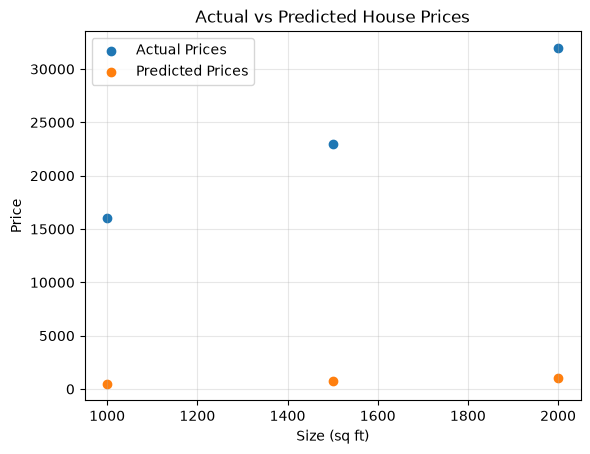

In [26]:
plt.scatter(X[:, 0], y, label="Actual Prices")
plt.scatter(X[:, 0], y_pred, label="Predicted Prices")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Size (sq ft)")
plt.ylabel("Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()